# 02 — Time-Series Exploration and Feature Engineering
Run after Notebook 01. ACF/PACF describe temporal dependence and motivate candidate lags; they do not determine the final lag by themselves. Notebook 03 selects among predeclared feature configurations using forecasting validation.

All lag diagnostics below use **2021–2022 development stations only**. Features for every prediction date use only observations strictly before that date. Calendar features are known in advance.

## 1. Load the prepared daily panel

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

# Locate code/ whether Jupyter starts in the project, code/, or code/script/.
CODE = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in [base, base / "code"]
             if (p / "script/01_data_preparation.ipynb").exists()), None)
if CODE is None:
    raise FileNotFoundError("Open this notebook from the project directory.")
DATA = CODE / "data"
RAW = DATA / "raw"
CONFIG = DATA / "config"
PROCESSED = DATA / "processed"
RESULT = CODE / "result"
TABLES = RESULT / "tables"
FIGURES = RESULT / "figures"
MODELS = RESULT / "models"
REPORTS = RESULT / "reports"
for folder in [PROCESSED, TABLES, FIGURES, MODELS, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project directory:", CODE)

Project directory: /Users/yigefeng/Desktop/WashU大三上/SDS4425/Project/code


In [2]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [3]:
panel = pd.read_csv(PROCESSED / "daily_panel.csv.gz", dtype={"station_id": str, "POC": str}, parse_dates=["date"])
initial = panel[(panel.role == "development") & (panel.date < "2023-01-01")]

## 2. Calculate station-level ACF and PACF
Use each station's longest uninterrupted observed segment, with at least 90 days. Never concatenate different stations or bridge missing dates before calculating autocorrelations. The cross-station median and interquartile range are descriptive summaries, not confidence intervals.

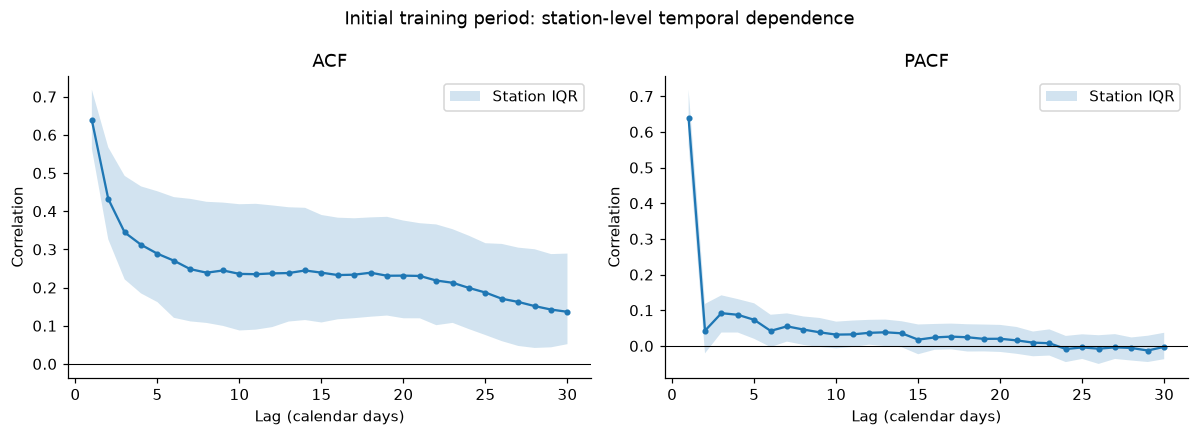

In [4]:
from statsmodels.tsa.stattools import acf, pacf
acf_rows, segments = [], {}
for sid, group in initial.groupby("station_id"):
    series = group.set_index("date").y.reindex(pd.date_range("2021-01-01", "2022-12-31"))
    observed = series.notna()
    run = (observed != observed.shift(fill_value=False)).cumsum()
    chunks = [chunk for _, chunk in series[observed].groupby(run[observed])]
    if not chunks:
        continue
    segment = max(chunks, key=len)
    if len(segment) < 90 or segment.std() < 1e-8:
        continue
    segments[sid] = segment
    ac = acf(segment, nlags=30, fft=True)
    pa = pacf(segment, nlags=30, method="ywm")
    for lag in range(1, 31):
        acf_rows.append({"station_id": sid, "lag": lag, "acf": ac[lag], "pacf": pa[lag], "segment_days": len(segment)})
acf_table = pd.DataFrame(acf_rows)
acf_table.to_csv(TABLES / "initial_period_acf_pacf.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["acf", "pacf"]):
    summary = acf_table.groupby("lag")[metric].quantile([.25, .5, .75]).unstack()
    ax.plot(summary.index, summary[.5], marker="o", markersize=3)
    ax.fill_between(summary.index, summary[.25], summary[.75], alpha=.2, label="Station IQR")
    ax.axhline(0, color="black", linewidth=.7)
    ax.set(title=metric.upper(), xlabel="Lag (calendar days)", ylabel="Correlation")
    ax.legend()
fig.suptitle("Initial training period: station-level temporal dependence")
save_figure(fig, "01_acf_pacf.png")

## 3. Plot representative histories and calendar seasonality

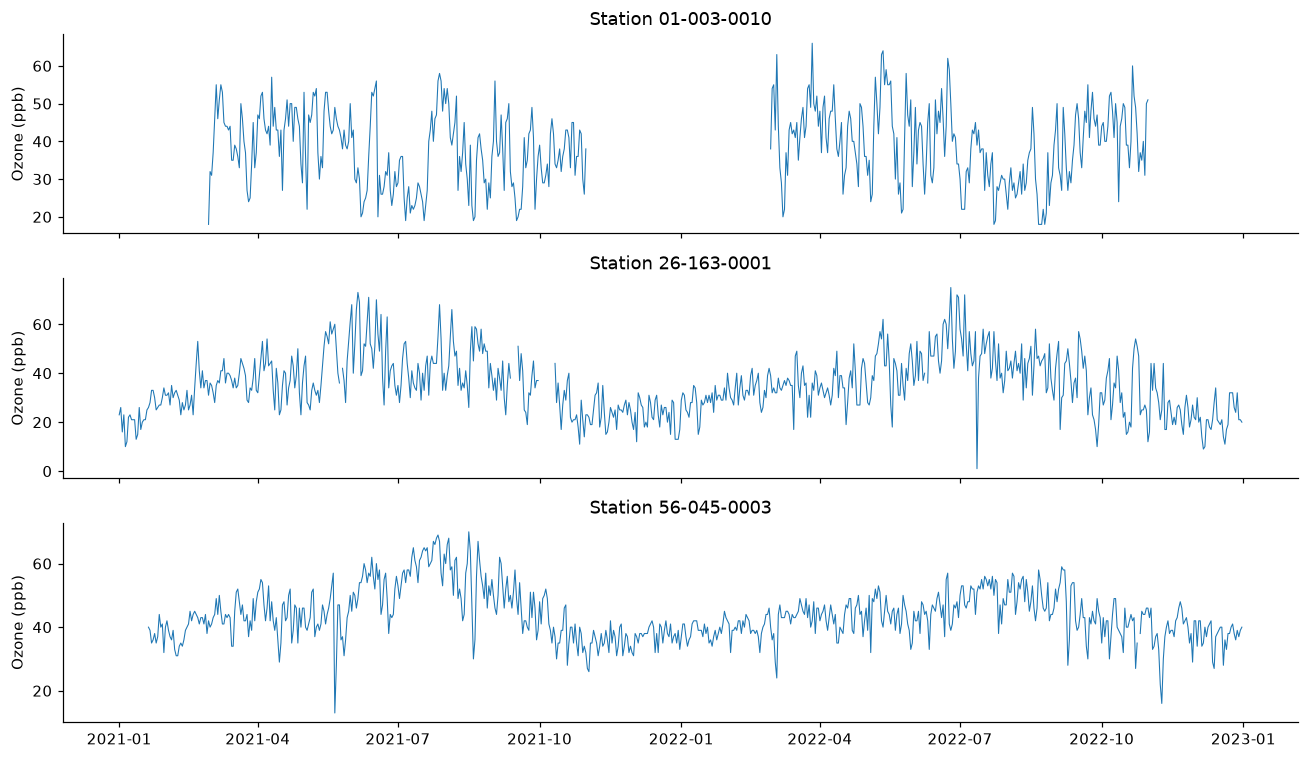

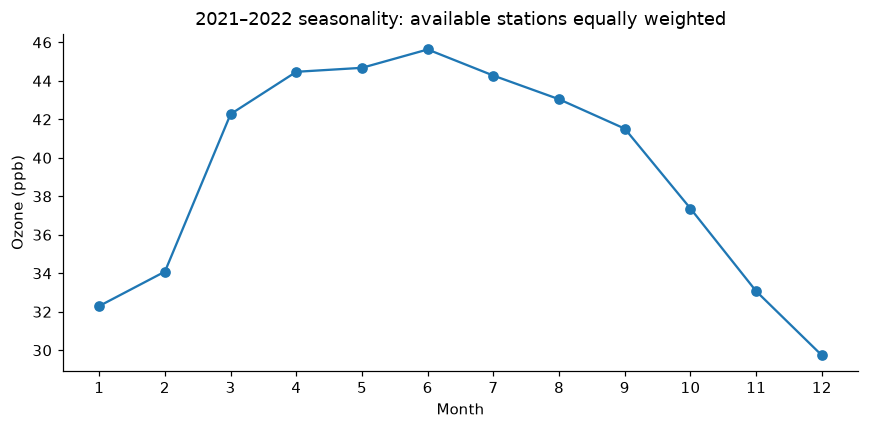

In [5]:
station_ids = sorted(segments)
representatives = [station_ids[i] for i in np.linspace(0, len(station_ids)-1, 3, dtype=int)]
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, sid in zip(axes, representatives):
    group = initial[initial.station_id == sid].set_index("date").y.reindex(pd.date_range("2021-01-01", "2022-12-31"))
    ax.plot(group.index, group, linewidth=.7)
    ax.set(title=f"Station {sid}", ylabel="Ozone (ppb)")
save_figure(fig, "02_station_time_series.png")
monthly = initial.assign(month=initial.date.dt.month).groupby(["station_id", "month"]).y.mean().reset_index()
seasonal = monthly.groupby("month").y.mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seasonal.index, seasonal.values, marker="o")
ax.set(xlabel="Month", ylabel="Ozone (ppb)", title="2021–2022 seasonality: available stations equally weighted", xticks=range(1,13))
save_figure(fig, "03_seasonality.png")

## 4. Construct causal daily features
For a target on date t, lag 1 is ozone on t−1. A lag setting of 3 includes lag 1, 2 and 3; it does not mean using only lag 3.

Candidates:
- Recent history: lags 1–1, 1–3, or 1–7.
- Rolling mean: 7, 14, or 28 preceding calendar days.
- Rolling standard deviation: 7, 14, or 28 preceding calendar days (sample SD, ddof=1).
- Target-date annual sine and cosine, always included.

There are 27 feature configurations. Every candidate is evaluated on the same complete-28-day-history sample. No missing-value imputation is performed. Standardization and spline knots are fitted later, inside each training fold, not here.

In [6]:
numeric = [f"lag{k}" for k in range(1, 8)] + [f"{stat}{w}" for stat in ["mean", "std"] for w in [7, 14, 28]]
calendar = ["sin", "cos"]
parts = []
for sid, group in panel.groupby("station_id"):
    y = group.set_index("date").y.reindex(pd.date_range("2021-01-01", "2025-12-31"))
    part = pd.DataFrame({"station_id": sid, "role": group.role.iloc[0],
                         "target_date": y.index, "target": y.values})
    history = y.shift(1)
    for lag in range(1, 8):
        part[f"lag{lag}"] = y.shift(lag).values
    for window in [7, 14, 28]:
        part[f"mean{window}"] = history.rolling(window, min_periods=window).mean().values
        part[f"std{window}"] = history.rolling(window, min_periods=window).std(ddof=1).values
    parts.append(part.dropna(subset=["target"] + numeric))
features = pd.concat(parts, ignore_index=True).sort_values(["target_date", "station_id"]).reset_index(drop=True)
phase = 2*np.pi*(features.target_date.dt.day_of_year-1)/np.where(features.target_date.dt.is_leap_year, 366, 365)
features["sin"] = np.sin(phase)
features["cos"] = np.cos(phase)
development = features[(features.role == "development") & (features.target_date < "2025-01-01")].copy()
test = features[features.target_date >= "2025-01-01"].copy()
assert development.target_date.max() < test.target_date.min()
assert not set(development.station_id) & set(test.loc[test.role == "held_out", "station_id"])
assert np.isfinite(features[numeric + calendar].to_numpy()).all()

## 5. Check feature timing and save separate datasets
The 2025 file includes both known and held-out stations. It represents rolling one-day-ahead forecasts: observed earlier test-day ozone may become a later day's predictor, while the final model coefficients stay frozen.

Pickle files preserve dates and types for the next notebooks. Load only these locally generated, trusted files. The compressed CSV panel and feature dictionary remain available for inspection.

In [7]:
lookup = panel.set_index(["station_id", "date"]).y
for _, row in features.sample(60, random_state=4425).iterrows():
    dates = pd.date_range(row.target_date-pd.Timedelta(days=28), row.target_date-pd.Timedelta(days=1))
    history = lookup.reindex(pd.MultiIndex.from_product([[row.station_id], dates]))
    assert history.notna().all()
    for lag in range(1,8):
        assert np.isclose(row[f"lag{lag}"], history.iloc[-lag])
    for window in [7,14,28]:
        assert np.isclose(row[f"mean{window}"], history.iloc[-window:].mean())
        assert np.isclose(row[f"std{window}"], history.iloc[-window:].std())
development.to_pickle(PROCESSED / "development_features.pkl.gz")
test.to_pickle(PROCESSED / "test_2025_features.pkl.gz")
feature_spec = {"numeric": numeric, "calendar": calendar, "lag_candidates": [1,3,7],
                "mean_windows": [7,14,28], "std_windows": [7,14,28], "common_history_days": 28}
(CONFIG / "feature_spec.json").write_text(json.dumps(feature_spec, indent=2))
dictionary = [{"feature": name, "description": (f"Observed ozone {name[3:]} days before target" if name.startswith("lag") else
               f"Prior {name[4:]}-day mean" if name.startswith("mean") else f"Prior {name[3:]}-day sample SD")} for name in numeric]
dictionary += [{"feature": "sin", "description": "Annual sine of target-date phase"},
               {"feature": "cos", "description": "Annual cosine of target-date phase"}]
pd.DataFrame(dictionary).to_csv(PROCESSED / "feature_dictionary.csv", index=False)
summary = pd.DataFrame([{"dataset": "development", "rows": len(development), "stations": development.station_id.nunique()},
                        {"dataset": "test_2025", "rows": len(test), "stations": test.station_id.nunique()}])
summary.to_csv(TABLES / "feature_sample_counts.csv", index=False)
display(summary)
print("60 calendar-window checks passed. Next: run 03_regression_models.ipynb")

,dataset,rows,stations
0,development,965281,971
1,test_2025,295815,1115


60 calendar-window checks passed. Next: run 03_regression_models.ipynb
